# Resampling Run Example

Resampling can be run from a notebook like this or via script (see scripts/smoke_resampling_sdxl.py)

In [1]:
from pathlib import Path
import time
import torch
from zigzag_project.model_utils import load_pipeline_standard
from zigzag_project.zsampling import make_initial_latents, resampling_sdxl
from zigzag_project.resampling_utils import ResamplingConfig, get_resampling_schedule

/home/lenka-hake/Documents/GM/generative-modelling/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:187: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12080). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
pipe = load_pipeline_standard("sdxl", device=device)

class ModelHandleWrapper:
    def __init__(self, pipeline):
        self.pipe = pipeline
        self.inverse_scheduler = pipeline.scheduler
        self.dtype = pipeline.unet.dtype
        self.device = pipeline.device
        self.hf_id = "stabilityai/stable-diffusion-xl-base-1.0"

handle = ModelHandleWrapper(pipe)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

effective j=1, r=1, clamped=False
schedule: [4, 3, 2, 1, 0, -1]
schedule length: 6
transitions: 5


  0%|          | 0/5 [00:00<?, ?it/s]

Runtime: 68.6s


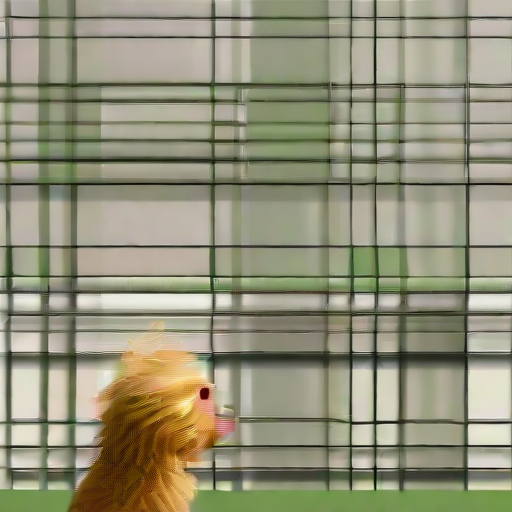

In [3]:
prompt = "a small yellow dog sitting on grass"
seed = 42
size = 512

config = ResamplingConfig(
    gamma_1=5.5,
    infer_step=5,   # DO NOT USE this for actual experiment. Use 50 as the paper says.
    jump_length=1,  # DO NOT USE this for actual experiment. Ideally, use 10, but can be adjusted.
    jump_n_sample=1 # DO NOT USE this for actual experiment. Ideally, use 10, but can be adjusted.
)

effective_j, effective_r, was_clamped = config.resolved_jump_params()
print(f"effective j={effective_j}, r={effective_r}, clamped={was_clamped}")

schedule = get_resampling_schedule(
    config.infer_step,
    jump_length=effective_j,
    jump_n_sample=effective_r,
)

print("schedule:", schedule)
print("schedule length:", len(schedule))
print("transitions:", len(schedule)-1)

latents = make_initial_latents(
    seed=seed,
    height=size,
    width=size,
    dtype=handle.dtype,
    device=handle.device
)

t0 = time.time()

result = resampling_sdxl(
    handle,
    prompt=prompt,
    config=config,
    height=size,
    width=size,
    latents=latents.clone()
)

print(f"Runtime: {time.time() - t0:.1f}s")
result.images[0]

In [4]:
out = Path("outputs/resampling_example_sdxl.png")
out.parent.mkdir(parents=True, exist_ok=True)
result.images[0].save(out)
out

PosixPath('outputs/resampling_example_sdxl.png')